1. Select the dataset and features
The dataset is the ARMPS 2010 Database worksheet from data in m.xlsx. For this assignment, the selected numerical features are:

- Depth of Cover (m) — depth of overburden above the mine.
- Mining Height1 (m) — mining/extraction height.
- Entry Width (m) — width of the roadway/entry.
- CMRR — Coal Mine Roof Rating, a rating of roof rock-mass conditions.

These features are selected because they represent mining geometry and roof conditions. Any available success/failure or roof-fall outcome column will not be used to create the clusters; it could only be examined after clustering if the column is present and its meaning is clear.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

FILE = "data in m.xlsx"
SHEET = "ARMPS 2010 Database"

df = pd.read_excel(FILE, sheet_name=SHEET)
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())
df.head()

Dataset shape: (645, 37)
Column names:
['State', 'Mine', 'Mining Height1 (m)', 'Depth of Cover (m)', 'Entry Width (m)', 'Crosscut Spacing (m)', 'Crosscut Angle (degrees)', 'Number of Entries', 'ECTR(1)2 (m)', 'ECTR(2) (m)', 'ECTR(3) (m)', 'ECTR(4) (m)', 'ECTR(5) (m)', 'ECTR(6) (m)', 'ECTR(7) (m)', 'ECTR(8) (m)', 'ECTR(9) (m)', 'Loading Condition', 'Front Gob Extent (m)', '1st Side Gob Extent (m)', '2nd Side Gob Extent (m)', '1st Barrier Pillar Width (m)', '2nd Barrier Pillar Width (m)', '1st Slab Cut Depth (m)', '2nd Slab Cut Depth (m)', 'CMRR', 'Roof Strength Rating3', 'Thickness of Caprock (cm)', 'Region', 'Number of cases', 'Weight', 'w2', 'Seam Strength', 'Hardgrove Index (HGI)', 'Success4', 'FailType5', 'Sort']


,State,Mine,Mining Height1 (m),Depth of Cover (m),Entry Width (m),Crosscut Spacing (m),Crosscut Angle (degrees),Number of Entries,ECTR(1)2 (m),ECTR(2) (m),...,Thickness of Caprock (cm),Region,Number of cases,Weight,w2,Seam Strength,Hardgrove Index (HGI),Success4,FailType5,Sort
0,AL,95,1.8288,350.520,6.096,30.480,90,5,26.8224,26.8224,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,510
1,AL,95,1.8288,350.520,6.096,39.624,90,9,39.6240,39.6240,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,1,1.0,511
2,AL,95,1.8288,350.520,6.096,27.432,90,10,27.4320,27.4320,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,512
3,CO,17,3.5052,243.840,6.096,27.432,90,10,25.9080,25.9080,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,1,1.0,76
4,CO,18,2.7432,475.488,6.096,21.336,90,6,39.6240,39.6240,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,0,4.0,77


In [3]:
df.columns = df.columns.astype(str).str.strip()

features = [
    "Depth of Cover (m)",
    "Mining Height1 (m)",
    "Entry Width (m)",
    "CMRR"
]

missing_columns = [c for c in features if c not in df.columns]
if missing_columns:
    raise KeyError(
        "These expected columns were not found: " + str(missing_columns) +
        "\nPlease inspect the printed column names above and update `features` to match the workbook exactly."
    )

X_raw = df[features].copy()
for col in features:
    X_raw[col] = pd.to_numeric(X_raw[col], errors="coerce")

print("Missing values in selected columns:")
display(X_raw.isna().sum().to_frame("missing_count"))

X = X_raw.dropna().copy()
print("Original rows:", len(df))
print("Rows available after dropping missing selected features:", len(X))
print("Rows excluded:", len(df) - len(X))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled.shape)

Missing values in selected columns:


,missing_count
Depth of Cover (m),0
Mining Height1 (m),0
Entry Width (m),0
CMRR,33


Original rows: 645
Rows available after dropping missing selected features: 612
Rows excluded: 33
Scaled data shape: (612, 4)


3. Apply K-means clustering
K-means assigns each mining case to a group based on similarity across the four standardised variables. We test several cluster counts, rather than assuming the best number in advance.

In [4]:
results = []
models = {}

max_k = min(8, len(X) - 1)
for k in range(2, max_k + 1):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    models[k] = (model, labels)
    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(X_scaled, labels),
        "smallest_cluster_size": int(pd.Series(labels).value_counts().min()),
        "largest_cluster_size": int(pd.Series(labels).value_counts().max())
    })

scores = pd.DataFrame(results)
display(scores.round(3))

,k,inertia,silhouette_score,smallest_cluster_size,largest_cluster_size
0,2,1796.215,0.325,285,327
1,3,1477.723,0.335,101,257
2,4,1239.464,0.363,54,252
3,5,1020.491,0.369,1,252
4,6,828.339,0.368,1,213
5,7,726.339,0.375,1,194
6,8,655.981,0.351,1,146


4. Explore different numbers of clusters and select an appropriate number

The elbow plot shows how within-cluster inertia changes as more clusters are added. The silhouette score compares how close observations are to their own cluster versus other clusters. A higher silhouette score generally suggests better-separated clusters, but engineering interpretability and cluster size also matter. The best score is a guide, not proof that the selected grouping is the only correct answer.

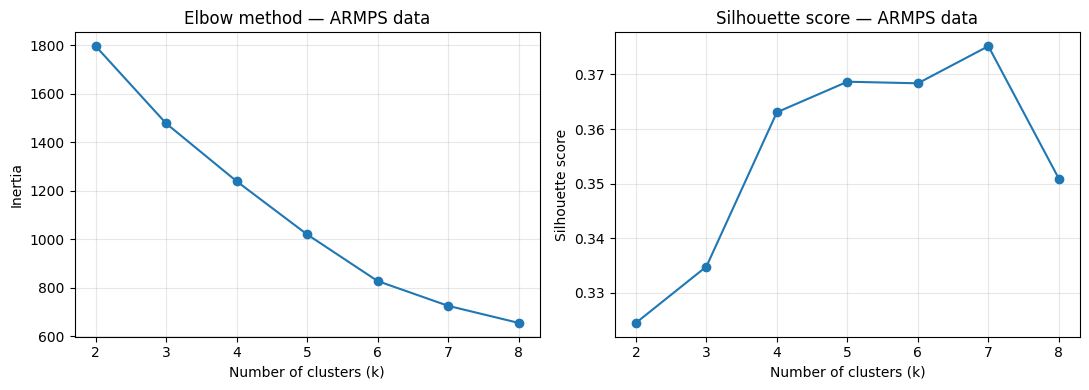

Candidate k with the highest silhouette score: 7
 k  inertia  silhouette_score  smallest_cluster_size  largest_cluster_size
 7  726.339             0.375                      1                   194


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(scores["k"], scores["inertia"], marker="o")
axes[0].set_title("Elbow method — ARMPS data")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(scores["k"], scores["silhouette_score"], marker="o")
axes[1].set_title("Silhouette score — ARMPS data")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_k = int(scores.loc[scores["silhouette_score"].idxmax(), "k"])
print("Candidate k with the highest silhouette score:", best_k)
print(scores.loc[scores["k"] == best_k].round(3).to_string(index=False))

5. Plot the clusters

PCA reduces the four-dimensional scaled data to two dimensions for a scatter plot. K-means was fitted using all four selected features; PCA is used only to display the results. The two-dimensional plot may not show every separation present in the original feature space.

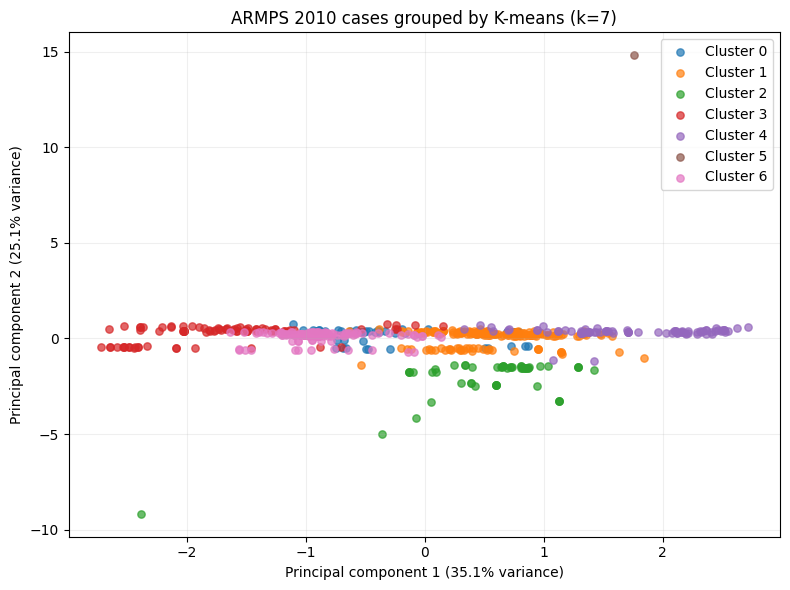

Variance represented by the first two principal components: 60.2%


In [6]:
best_model, labels = models[best_k]
clustered = X.copy()
clustered["Cluster"] = labels

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for cid in sorted(np.unique(labels)):
    mask = labels == cid
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.7, label=f"Cluster {cid}")
plt.title(f"ARMPS 2010 cases grouped by K-means (k={best_k})")
plt.xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("Variance represented by the first two principal components:",
      f"{pca.explained_variance_ratio_.sum()*100:.1f}%")

In [7]:
cluster_sizes = clustered["Cluster"].value_counts().sort_index().rename("number_of_cases")
display(cluster_sizes.to_frame())

cluster_means = clustered.groupby("Cluster")[features].mean().round(3)
cluster_medians = clustered.groupby("Cluster")[features].median().round(3)

print("Mean feature values by cluster:")
display(cluster_means)
print("Median feature values by cluster:")
display(cluster_medians)

# Optional post-hoc comparison only: display potential outcome columns if present.
possible_outcome_cols = [
    c for c in df.columns
    if any(term in c.lower() for term in ["success", "failure", "roof fall", "roof_fall", "stable", "unstable"])
]
print("Potential outcome columns found (not used for clustering):", possible_outcome_cols)

if possible_outcome_cols:
    print("Inspect these columns and confirm their definitions before any post-hoc comparison.")


,number_of_cases
Cluster,
0,48
1,194
2,54
3,86
4,82
5,1
6,147


Mean feature values by cluster:


,Depth of Cover (m),Mining Height1 (m),Entry Width (m),CMRR
Cluster,,,,
0,238.550,2.886,6.010,3.938
1,255.162,1.593,6.036,55.387
2,179.122,1.836,5.300,36.963
3,513.723,2.107,6.025,10.733
4,149.278,2.742,6.081,64.512
5,91.440,2.134,11.125,50.000
6,287.211,1.543,6.064,4.122


Median feature values by cluster:


,Depth of Cover (m),Mining Height1 (m),Entry Width (m),CMRR
Cluster,,,,
0,262.128,2.743,6.096,4.0
1,259.080,1.600,6.096,52.0
2,173.393,1.829,5.486,44.0
3,510.540,2.088,6.096,5.0
4,121.920,2.743,6.096,64.0
5,91.440,2.134,11.125,50.0
6,289.560,1.524,6.096,5.0


Potential outcome columns found (not used for clustering): ['Success4']
Inspect these columns and confirm their definitions before any post-hoc comparison.


### Discussion of K-means Clustering Results

**1. Selection of the number of clusters**

The K-means clustering analysis produced seven clusters, labelled Cluster 0 to Cluster 6. The final choice of the number of clusters should be assessed using both the silhouette score and the elbow plot. The silhouette score identifies how well-separated the clusters are, while the elbow plot helps identify the point at which increasing the number of clusters produces diminishing improvements in within-cluster variation. The highest silhouette score was obtained at *k* = 7. The elbow plot 2 this choice. Therefore, the suitability of seven clusters should be confirmed against these evaluation plots.

**2. Description of the clusters**

The analysis produced 612 cases distributed across seven clusters. Table 1 summarises their sizes and mean feature values.

| Cluster | Cases | Depth of cover (m) | Mining height (m) | Entry width (m) | Mean CMRR |
|---|---:|---:|---:|---:|---:|
| 0 | 48 | 238.550 | 2.886 | 6.010 | 3.938 |
| 1 | 194 | 255.162 | 1.593 | 6.036 | 55.387 |
| 2 | 54 | 179.122 | 1.836 | 5.300 | 36.963 |
| 3 | 86 | 513.723 | 2.107 | 6.025 | 10.733 |
| 4 | 82 | 149.278 | 2.742 | 6.081 | 64.512 |
| 5 | 1 | 91.440 | 2.134 | 11.125 | 50.000 |
| 6 | 147 | 287.211 | 1.543 | 6.064 | 4.122 |

Cluster 1 was the largest group, containing 194 cases, followed by Cluster 6 with 147 cases. Cluster 5 was the smallest, containing only one case. The clusters differ in their average depth of cover, mining height, entry width and Coal Mine Roof Rating (CMRR).

- **Cluster 0:** Contains 48 cases, with a mean depth of cover of 238.550 m, mining height of 2.886 m, entry width of 6.010 m and CMRR of 3.938.
- **Cluster 1:** Contains 194 cases, with a mean depth of cover of 255.162 m, mining height of 1.593 m, entry width of 6.036 m and CMRR of 55.387.
- **Cluster 2:** Contains 54 cases, with a mean depth of cover of 179.122 m, mining height of 1.836 m, entry width of 5.300 m and CMRR of 36.963.
- **Cluster 3:** Contains 86 cases, with a mean depth of cover of 513.723 m, mining height of 2.107 m, entry width of 6.025 m and CMRR of 10.733.
- **Cluster 4:** Contains 82 cases, with a mean depth of cover of 149.278 m, mining height of 2.742 m, entry width of 6.081 m and CMRR of 64.512.
- **Cluster 5:** Contains one case, with a depth of cover of 91.440 m, mining height of 2.134 m, entry width of 11.125 m and CMRR of 50.000. Its unusually wide entry makes it important to inspect this case separately.
- **Cluster 6:** Contains 147 cases, with a mean depth of cover of 287.211 m, mining height of 1.543 m, entry width of 6.064 m and CMRR of 4.122.

**3. Interpretation in mining terms**

The clusters represent groups of mining cases with similar combinations of mining geometry and roof-rating conditions. For example, Cluster 3 has the greatest average depth of cover (513.723 m) and a low mean CMRR of 10.733. Cluster 4 has a comparatively shallow average cover of 149.278 m, a higher mining height of 2.742 m and a mean CMRR of 64.512. These differences illustrate how the clustering process separates cases with contrasting geological and mining characteristics.

Clusters 0 and 6 also have low mean CMRR values, while Cluster 1 has a substantially higher mean CMRR and a lower average mining height. These patterns may help identify combinations of conditions for further geotechnical investigation. However, the clusters alone do not establish the actual stability or failure probability of the excavations. Cluster 5 requires particular attention because it contains only one case and has an entry width considerably greater than the other cluster averages.

**4. Limitations of the analysis**

Several limitations should be considered when interpreting the results. First, missing CMRR values reduce the number of cases available for clustering and may affect how representative the resulting groups are. Second, the ARMPS database represents general coal-mining cases and is not necessarily representative of the geological, geotechnical and operational conditions at Morupule Coal Mine. Third, K-means clustering is sensitive to feature scaling and outliers, so the results depend on appropriate preprocessing and the treatment of unusual observations. The single case in Cluster 5 illustrates why cluster sizes and unusual feature values should be examined carefully. Finally, clustering is an unsupervised learning technique: the resulting groups are not roof-fall predictions and should not be interpreted as validated risk categories.

If the dataset contains a failure outcome, such as the `Success4` column identified in the notebook, that outcome was not used to create the clusters. Any subsequent comparison between cluster membership and this outcome would be exploratory. The outcome's definition and coding must first be confirmed, and such a comparison would not independently validate a roof-fall prediction model.

